# Customer Segmentation with Agglomerative Hierarchical Clustering (RFM)

**Business question.** A UK online gift retailer sells mostly to small wholesale customers. Which groups of customers behave alike in how *recently*, how *often* and how *much* they buy, and which groups deserve retention, reactivation or no further effort?

**Approach**
1. Clean one year of transactions (Dec 2010 to Dec 2011)
2. Build Recency, Frequency and Monetary (RFM) features per customer
3. Fix heavy skew before clustering
4. Compare linkage methods (single, complete, average, Ward) with the cophenetic correlation and cluster-size balance
5. Choose the number of segments from the dendrogram and silhouette scores
6. Profile and name the segments, then quantify revenue concentration
7. Cross-check against K-Means

**Data:** run `python scripts/download_data.py` once to download the UCI *Online Retail* file into `data/` (see README).

## How agglomerative clustering works
Start with every customer as its own cluster, then repeatedly merge the two *closest* clusters until one remains. The full merge history is a tree (the **dendrogram**), and cutting it at any height gives a clustering. The **linkage** rule defines "closest":
- **Single:** nearest pair of points. Can form long chains.
- **Complete:** farthest pair of points. Produces compact clusters.
- **Average:** mean of all pairwise distances.
- **Ward:** the merge that increases total within-cluster variance the least. Produces balanced, spherical clusters.

Unlike K-Means, the number of clusters is not fixed in advance, and the dendrogram shows how stable each grouping is across scales.

## 1. Setup and Cleaning

In [1]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.cluster import KMeans
RANDOM_STATE = 42
FIG_DIR, MET_DIR = Path('../outputs/figures'), Path('../outputs/metrics')
FIG_DIR.mkdir(parents=True, exist_ok=True); MET_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid'); plt.rcParams.update({'figure.dpi': 110})

In [2]:
DATA = Path('../data/OnlineRetail.csv')
assert DATA.exists(), 'Run `python scripts/download_data.py` from the repository root first.'
raw = pd.read_csv(DATA, encoding='cp1252', dtype={'InvoiceNo': str, 'CustomerID': 'float64'})
print('Raw transactions:', raw.shape)
audit = {'Missing CustomerID': raw['CustomerID'].isna().sum(),
         'Cancelled invoices (start with C)': raw['InvoiceNo'].str.startswith('C').sum(),
         'Quantity <= 0': (raw['Quantity'] <= 0).sum(), 'UnitPrice <= 0': (raw['UnitPrice'] <= 0).sum(),
         'Exact duplicate lines': raw.duplicated().sum()}
display(pd.Series(audit, name='Rows').to_frame().assign(Share=lambda d: (d['Rows'] / len(raw)).round(4)))

Raw transactions: (541909, 7)


,Rows,Share
Missing CustomerID,135080,0.2493
Cancelled invoices (start with C),9288,0.0171
Quantity <= 0,10624,0.0196
UnitPrice <= 0,2517,0.0046
Exact duplicate lines,5338,0.0099


**Observation:** 541,909 transaction lines. A quarter (24.9%) have no CustomerID and cannot be attributed to a customer. A further 1.7% are cancellations, 2.0% have non-positive quantity, 0.5% have zero or negative price, and 1.0% are exact duplicate lines.

In [3]:
df = raw.dropna(subset=['CustomerID'])
df = df[~df['InvoiceNo'].str.startswith('C')]
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)].drop_duplicates()
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%d-%m-%Y %H:%M')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
print(f'Clean transactions: {len(df):,} ({len(df) / len(raw):.1%} of raw) | customers: {df.CustomerID.nunique():,} | '
      f'period: {df.InvoiceDate.min():%d %b %Y} to {df.InvoiceDate.max():%d %b %Y}')
print('UK share of revenue: {:.1%}'.format(df.loc[df.Country == 'United Kingdom', 'Revenue'].sum() / df.Revenue.sum()))

Clean transactions: 392,657 (72.5% of raw) | customers: 4,338 | period: 01 Dec 2010 to 09 Dec 2011
UK share of revenue: 82.0%


**Observation:** After cleaning, 392,657 lines (72.5%) remain, covering 4,338 customers from 1 December 2010 to 9 December 2011. The UK accounts for 82% of revenue.

## 2. RFM Features

In [4]:
snapshot = df['InvoiceDate'].max() + pd.Timedelta(days=1)
rfm = df.groupby('CustomerID').agg(Recency=('InvoiceDate', lambda d: (snapshot - d.max()).days),
                                   Frequency=('InvoiceNo', 'nunique'), Monetary=('Revenue', 'sum'))
print('Customers:', len(rfm))
display(rfm.describe(percentiles=[0.25, 0.5, 0.75, 0.95, 0.99]).T.round(1))
print('Skewness:', rfm.skew().round(1).to_dict())

Customers: 4338


,count,mean,std,min,25%,50%,75%,95%,99%,max
Recency,4338.0,92.5,100.0,1.0,18.0,51.0,142.0,312.0,369.0,374.0
Frequency,4338.0,4.3,7.7,1.0,1.0,2.0,5.0,13.0,30.0,209.0
Monetary,4338.0,2048.6,8985.2,3.8,306.5,668.6,1660.6,5790.0,19780.5,280206.0


Skewness: {'Recency': 1.2, 'Frequency': 12.1, 'Monetary': 19.3}


**Observation:** RFM is extremely skewed. The median customer bought 2 times for GBP 669, but the top 1% bought 30+ times and spent GBP 19,800+, and the largest customer spent GBP 280,206. Skewness is 12.1 for frequency and 19.3 for monetary value. On raw scales, distance-based clustering would be dominated by a handful of outliers.

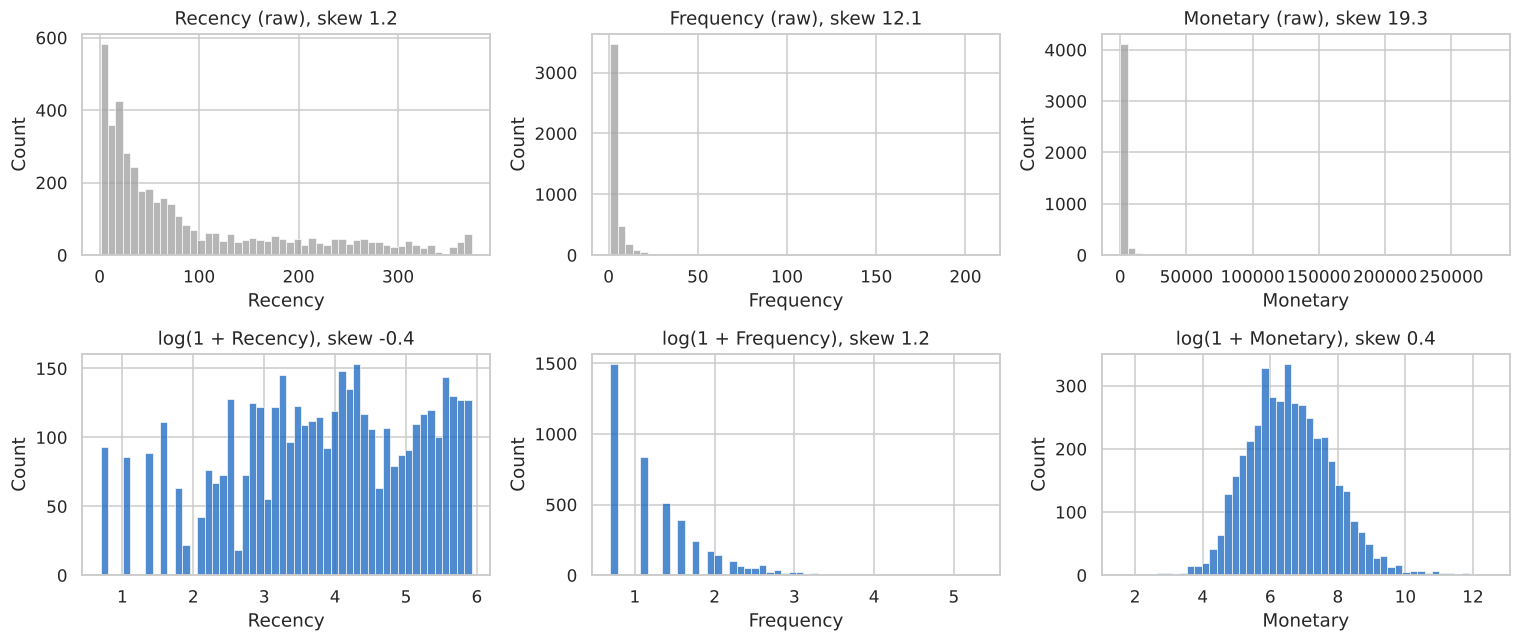

In [5]:
rfm_log = np.log1p(rfm)
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
for i, c in enumerate(rfm.columns):
    sns.histplot(rfm[c], bins=50, ax=axes[0, i], color='#9E9E9E'); axes[0, i].set_title(f'{c} (raw), skew {rfm[c].skew():.1f}')
    sns.histplot(rfm_log[c], bins=50, ax=axes[1, i], color='#1565C0'); axes[1, i].set_title(f'log(1 + {c}), skew {rfm_log[c].skew():.1f}')
plt.tight_layout(); plt.savefig(FIG_DIR / 'rfm_skew_raw_vs_log.png', bbox_inches='tight'); plt.show()
X = StandardScaler().fit_transform(rfm_log)                 # features used for clustering
X_minmax_raw = MinMaxScaler().fit_transform(rfm)            # the common naive alternative, for comparison

**Observation:** `log(1 + x)` reduces skewness to near zero and makes the distributions usable for Euclidean distance. The common alternative, min-max scaling of raw values, keeps the skew: most customers are compressed into the bottom 1-2% of the range.

## 3. Comparing Linkage Methods
For each linkage: the **cophenetic correlation** (how faithfully the tree preserves the original pairwise distances), and the cluster sizes when the tree is cut into 4 groups.

In [6]:
d_log, d_raw = pdist(X), pdist(X_minmax_raw)
rows, Z = [], {}
for method in ['single', 'complete', 'average', 'ward']:
    for name, data, d in [('log + standardised', X, d_log), ('raw min-max', X_minmax_raw, d_raw)]:
        L = linkage(data, method=method)
        sizes = np.sort(np.bincount(fcluster(L, 4, criterion='maxclust'))[1:])[::-1]
        rows.append({'Linkage': method, 'Scaling': name, 'Cophenetic r': cophenet(L, d)[0],
                     'Sizes at k=4': ', '.join(map(str, sizes)), 'Largest cluster share': sizes[0] / len(data)})
        if name == 'log + standardised': Z[method] = L
link_tbl = pd.DataFrame(rows)
display(link_tbl.round(3))
link_tbl.round(4).to_csv(MET_DIR / 'linkage_comparison.csv', index=False)

,Linkage,Scaling,Cophenetic r,Sizes at k=4,Largest cluster share
0,single,log + standardised,0.488,"4333, 3, 1, 1",0.999
1,single,raw min-max,0.335,"4335, 1, 1, 1",0.999
2,complete,log + standardised,0.577,"2467, 1820, 47, 4",0.569
3,complete,raw min-max,0.866,"3380, 940, 11, 7",0.779
4,average,log + standardised,0.676,"4290, 44, 3, 1",0.989
5,average,raw min-max,0.888,"3706, 625, 5, 2",0.854
6,ward,log + standardised,0.610,"1716, 1517, 762, 343",0.396
7,ward,raw min-max,0.813,"1965, 1184, 605, 584",0.453


**Observation:** Linkage choice dominates the result. Single and average linkage chain almost everyone into one cluster (4,333 and 4,290 of 4,338 at k = 4), which makes them useless for segmentation despite reasonable cophenetic correlations. Complete linkage still gives one cluster of 57%. **Ward linkage on log-scaled data** is the only setting that produces four usable segments (1,716 / 1,517 / 762 / 343). The cophenetic correlation is higher for raw min-max data, but that mainly reflects how well the tree preserves distances to outliers, not how useful the segments are.

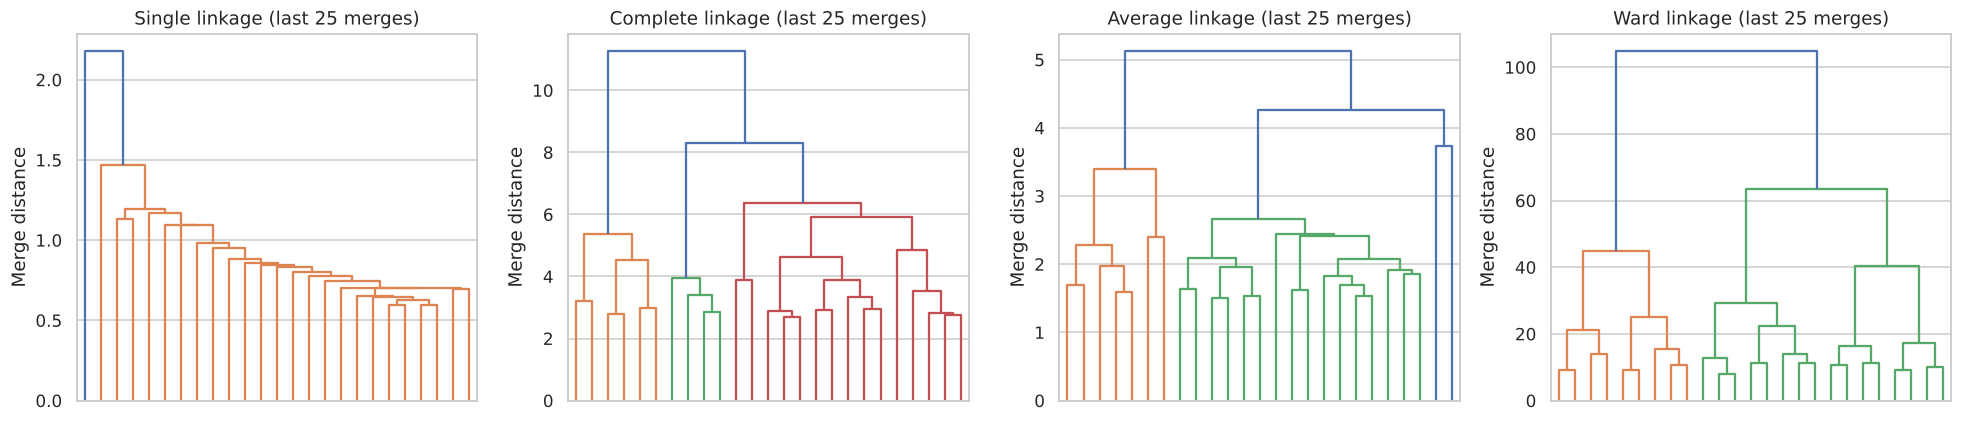

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, m in zip(axes, ['single', 'complete', 'average', 'ward']):
    dendrogram(Z[m], truncate_mode='lastp', p=25, ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f'{m.title()} linkage (last 25 merges)'); ax.set_ylabel('Merge distance')
plt.tight_layout(); plt.savefig(FIG_DIR / 'dendrograms_by_linkage.png', bbox_inches='tight'); plt.show()

**Observation:** The single-linkage dendrogram shows the classic chaining staircase. Complete, average and Ward produce progressively more balanced top-level merges, and Ward has the clearest large-scale structure.

## 4. Choosing the Number of Segments (Ward linkage)

In [8]:
sil = []
for k in range(2, 9):
    lab = fcluster(Z['ward'], k, criterion='maxclust')
    sil.append({'k': k, 'Silhouette': silhouette_score(X, lab), 'Smallest segment': np.bincount(lab)[1:].min()})
sil_tbl = pd.DataFrame(sil); display(sil_tbl.round(3)); sil_tbl.round(4).to_csv(MET_DIR / 'ward_k_selection.csv', index=False)
heights = Z['ward'][-10:, 2][::-1]
print('Last 9 merge heights (largest first):', np.round(heights, 1))
print('Height jumps:', np.round(-np.diff(heights), 1))

,k,Silhouette,Smallest segment
0,2,0.404,1105
1,3,0.284,1105
2,4,0.280,343
3,5,0.281,343
4,6,0.266,343
5,7,0.258,211
6,8,0.252,211


Last 9 merge heights (largest first): [104.8  63.5  44.9  40.5  29.2  25.2  22.4  21.   17.2  16.3]
Height jumps: [41.3 18.6  4.4 11.3  4.   2.8  1.4  3.8  0.9]


**Observation:** Statistically, the cleanest cut is k = 2 (silhouette 0.404, with the largest gap in merge heights). Between k = 3 and k = 5 the silhouette is flat (0.28) and the dendrogram gaps are modest. **k = 4** is chosen for business use: it separates a small, high-value group that k = 2 and k = 3 merge into larger segments, at no cost in silhouette. This is a judgement call, and the segments should be read as useful divisions of a continuum rather than natural clusters.

In [9]:
K = 4
labels = fcluster(Z['ward'], K, criterion='maxclust')
rfm['Segment_id'] = labels
prof = rfm.groupby('Segment_id').agg(Customers=('Recency', 'size'), Recency_median=('Recency', 'median'),
                                     Frequency_median=('Frequency', 'median'), Monetary_median=('Monetary', 'median'),
                                     Revenue=('Monetary', 'sum'))
prof['Customer share'] = prof['Customers'] / prof['Customers'].sum()
prof['Revenue share'] = prof['Revenue'] / prof['Revenue'].sum()
# Name segments by their RFM medians: best (low recency, high F and M) to worst
score = prof['Recency_median'].rank() - prof['Frequency_median'].rank() - prof['Monetary_median'].rank()
order = score.sort_values().index
names = dict(zip(order, ['Champions', 'Loyal regulars', 'Lapsing', 'Lost / one-off']))
prof['Segment'] = prof.index.map(names); rfm['Segment'] = rfm['Segment_id'].map(names)
prof = prof.set_index('Segment').loc[['Champions', 'Loyal regulars', 'Lapsing', 'Lost / one-off']]
display(prof.round(3))
prof.round(4).to_csv(MET_DIR / 'segment_profiles.csv')

,Customers,Recency_median,Frequency_median,Monetary_median,Revenue,Customer share,Revenue share
Segment,,,,,,,
Champions,343,9.0,15.0,6127.43,4678735.080,0.079,0.526
Loyal regulars,762,8.0,5.0,1451.95,1380069.430,0.176,0.155
Lapsing,1517,67.0,3.0,1021.48,2364382.853,0.350,0.266
Lost / one-off,1716,117.0,1.0,251.61,463846.631,0.396,0.052


**Observation:** The four segments differ clearly. **Champions** (343 customers, 8%): bought 9 days ago (median), 15 orders, GBP 6,127. **Loyal regulars** (762, 18%): recent (8 days), 5 orders, GBP 1,452. **Lapsing** (1,517, 35%): last order 67 days ago, 3 orders, GBP 1,021. **Lost / one-off** (1,716, 40%): 117 days, 1 order, GBP 252.

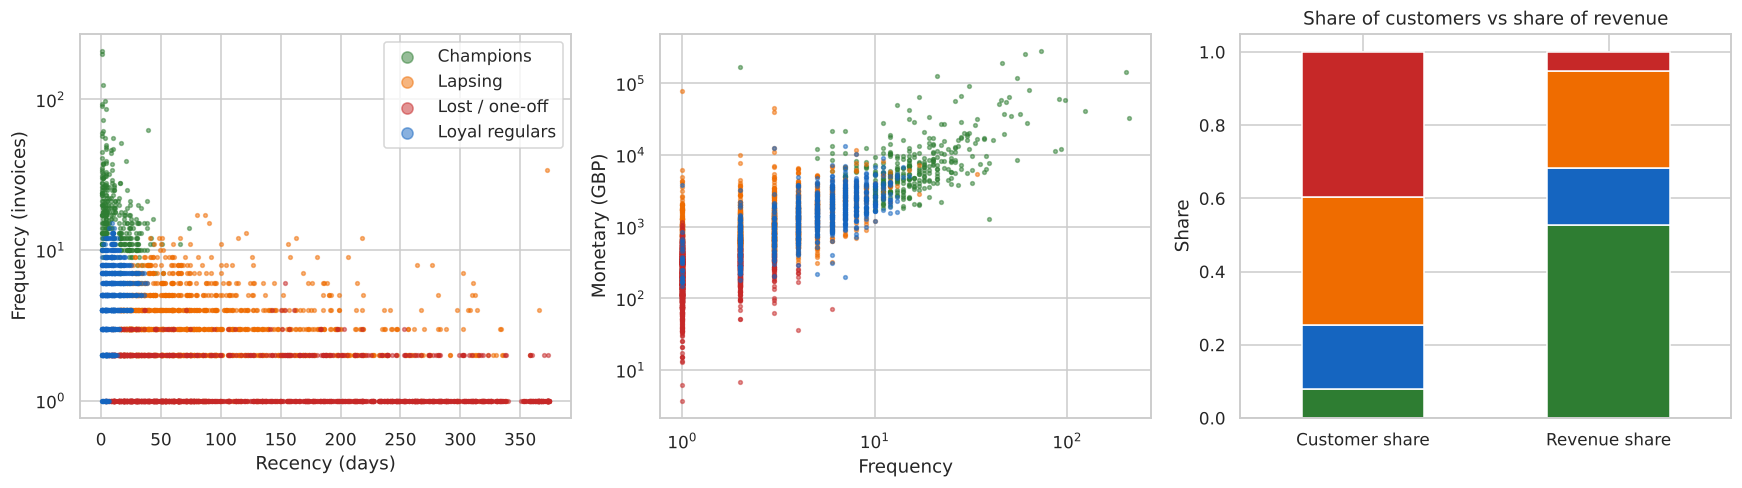

In [10]:
pal = {'Champions': '#2E7D32', 'Loyal regulars': '#1565C0', 'Lapsing': '#EF6C00', 'Lost / one-off': '#C62828'}
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for seg, sub in rfm.groupby('Segment'):
    axes[0].scatter(sub['Recency'], sub['Frequency'], s=6, alpha=0.5, color=pal[seg], label=seg)
    axes[1].scatter(sub['Frequency'], sub['Monetary'], s=6, alpha=0.5, color=pal[seg])
axes[0].set_xlabel('Recency (days)'); axes[0].set_ylabel('Frequency (invoices)'); axes[0].set_yscale('log'); axes[0].legend(markerscale=3)
axes[1].set_xlabel('Frequency'); axes[1].set_ylabel('Monetary (GBP)'); axes[1].set_xscale('log'); axes[1].set_yscale('log')
share = prof[['Customer share', 'Revenue share']]
share.T.plot.bar(stacked=True, ax=axes[2], color=[pal[s] for s in share.index], rot=0, legend=False)
axes[2].set_title('Share of customers vs share of revenue'); axes[2].set_ylabel('Share')
plt.tight_layout(); plt.savefig(FIG_DIR / 'segments_rfm.png', bbox_inches='tight'); plt.show()

**Observation:** Champions are 7.9% of customers but generate **52.6% of revenue**. Lost / one-off customers are 39.6% of customers and only 5.2% of revenue. The Lapsing segment still holds 26.6% of revenue, which makes it the obvious reactivation target: those customers have bought several times but are drifting away.

## 5. Cross-Check Against K-Means

In [11]:
km = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
print(f'Adjusted Rand Index, Ward vs K-Means (k = {K}): {adjusted_rand_score(labels, km.labels_):.3f}')
print(f'Silhouette - Ward: {silhouette_score(X, labels):.3f} | K-Means: {silhouette_score(X, km.labels_):.3f}')
display(pd.crosstab(rfm['Segment'], km.labels_, rownames=['Ward segment'], colnames=['K-Means cluster']))

Adjusted Rand Index, Ward vs K-Means (k = 4): 0.430


Silhouette - Ward: 0.280 | K-Means: 0.337


K-Means cluster,0,1,2,3
Ward segment,,,,
Champions,0,3,0,340
Lapsing,326,1016,146,29
Lost / one-off,1291,2,423,0
Loyal regulars,0,152,270,340


**Observation:** K-Means on the same features agrees only moderately with Ward (ARI 0.43) and scores a higher silhouette (0.337 vs 0.280). The **Champions segment is robust**: 340 of 343 fall in a single K-Means cluster. The boundaries between Loyal, Lapsing and Lost depend on the algorithm. The top segment is a dependable finding, while the lower three are a reasonable but method-dependent division.

## 6. Revenue Concentration

In [12]:
m_sorted = rfm['Monetary'].sort_values(ascending=False)
cum = m_sorted.cumsum() / m_sorted.sum()
for p in [0.01, 0.05, 0.2]:
    print(f'Top {p:.0%} of customers generate {cum.iloc[int(p * len(cum)) - 1]:.1%} of revenue')

Top 1% of customers generate 31.8% of revenue
Top 5% of customers generate 50.4% of revenue
Top 20% of customers generate 74.7% of revenue


**Observation:** Revenue is highly concentrated. The top 1% of customers generate 31.8% of revenue, the top 5% generate 50.4%, and the top 20% generate 74.7%, slightly steeper than the classic 80/20 rule. Losing a few dozen accounts would materially affect revenue.

# Conclusion

| Segment | Customers | Median recency (days) | Median orders | Median spend (GBP) | Revenue share | Suggested action |
|---|---|---|---|---|---|---|
| Champions | 343 (8%) | 9 | 15 | 6,127 | 52.6% | Account management, retention |
| Loyal regulars | 762 (18%) | 8 | 5 | 1,452 | 15.5% | Cross-sell, grow towards champion |
| Lapsing | 1,517 (35%) | 67 | 3 | 1,021 | 26.6% | Reactivation campaigns |
| Lost / one-off | 1,716 (40%) | 117 | 1 | 252 | 5.2% | Low-cost automated contact only |

**Findings**
1. Log-scaling RFM and using Ward linkage are what make hierarchical clustering useful here. Single and average linkage collapse into one giant cluster.
2. 8% of customers (Champions) generate more than half of revenue, and this segment is stable across methods.
3. The Lapsing segment holds about a quarter of revenue and is the highest-value reactivation target.
4. The divisions below the Champions are method-dependent (ARI 0.43 vs K-Means) and should be treated as working segments, not fixed truths.

**Limitations:** One year of data from a single, mostly wholesale UK retailer. Transactions without a CustomerID (25% of lines) are excluded. RFM ignores product mix and margin. The choice of k = 4 is partly a business judgement.